# Neural Network Training Notebook

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import netCDF4
from pathlib import Path
from datetime import datetime
import json
import torch
import copy
import inspect

In [2]:
import torch.nn as nn
from torch.utils.data import Subset, DataLoader

In [3]:
from helpers.data_funcs import make_index #need to restart kernel to get these updated!!
from helpers.data_funcs import IcepackDataset
from helpers.data_funcs import read_mod_file
from helpers.models_funcs import train
from helpers.models_funcs import validate
from helpers.models_funcs import evaluate
from helpers.models_funcs import unpack

In [4]:
from helpers.network_architectures import *

## Config

In [5]:
choice = "CNN"
loss_choice = "MSE"
other_options = {}
EXPERIMENT_NAME = "CNN_MSE_default"


RUN_NAME = "ksno16"
SPLIT_NAME = "split1_enthalpy"

In [6]:
def blank_optimizer(model):
    return torch.optim.Adam(model.parameters())



SEED = 2
epochs = 2500
batch_size = 16
loss_dict = LOSS_CHOICES[loss_choice]
loss_fn = loss_dict["loss"]
other_options["unknowns"] = loss_dict["unknowns"]
patience = 250 #number of epochs without improvment before pulling the plug

## Loading Data

In [7]:
torch.manual_seed(SEED)
IN_DIR = Path(f"/projects/dagr5998/cleaned_data/01icepack_array_output/{RUN_NAME}_daily")
SPLIT_DIR = Path(f"/projects/dagr5998/cleaned_data/02icepack_split_output/{RUN_NAME}_split/{SPLIT_NAME}")
OUT_DIR = Path(f"/projects/dagr5998/cleaned_data/03icepack_experiment_output/{RUN_NAME}/{SPLIT_NAME}/{EXPERIMENT_NAME}")

In [8]:
X = np.load(IN_DIR / "X.npy") # input array
Y = np.load(IN_DIR / "Y.npy") # output array
sets = np.load(IN_DIR / "sets.npy") # changed parameter set index
parameterizations = np.load(IN_DIR / "parameterizations.npy") # changed parameterizations
locations = np.load(IN_DIR/"locations.npy") 

In [9]:
mu,sd = np.load(SPLIT_DIR / 'mu.npy'), np.load (SPLIT_DIR/'sd.npy')
mu,sd = torch.from_numpy(mu), torch.from_numpy(sd)
train_index = np.load (SPLIT_DIR/"train_index.npy")
train_ind = np.load (SPLIT_DIR/"train_ind.npy")
val_index = np.load (SPLIT_DIR/"val_index.npy")
val_ind = np.load (SPLIT_DIR/"val_ind.npy")

In [10]:
with open(IN_DIR / 'config.json') as f:
    config = json.load(f)
with open(SPLIT_DIR / 'split_config.json') as f:
    split_config = json.load(f)
var_ind_list = split_config["var_ind_list"]
Xt = torch.from_numpy(X[:, :, var_ind_list].copy())
Yt = torch.from_numpy(Y)

In [11]:
training_vars = split_config["training_vars"]
input_window = split_config["input_window_timesteps"]

In [12]:
assert Xt.shape[2] == len(training_vars) #same channels
assert Yt.shape[0] == Xt.shape[0] #same number of runs
assert Path(split_config["in_path"])== (IN_DIR) #same data
assert split_config["n_train"] == len(train_index)

In [13]:
train_ds = IcepackDataset(Xt, Yt, train_index, input_window,mu,sd)
val_ds = IcepackDataset(Xt, Yt, val_index, input_window, mu,sd)

## Testing Training Loop

In [14]:
picks = []
for set_i in np.unique(sets[train_ind]):
    for i, l in enumerate(train_index):
        if sets[l[0]] == set_i and locations[l[0]] == "centralarctic" and l[1] == 0:
            picks.append(i)

In [15]:
xbatch, ybatch = next(iter(DataLoader(Subset(train_ds, picks), batch_size=5)))
y_mu, y_sd = Yt[train_ind].mean(0), Yt[train_ind].std(0)
ybatch_01 = (ybatch-y_mu)/y_sd
print(xbatch.shape, ybatch.shape)

torch.Size([5, 365, 36]) torch.Size([5, 1])


In [16]:
xbatch.shape

torch.Size([5, 365, 36])

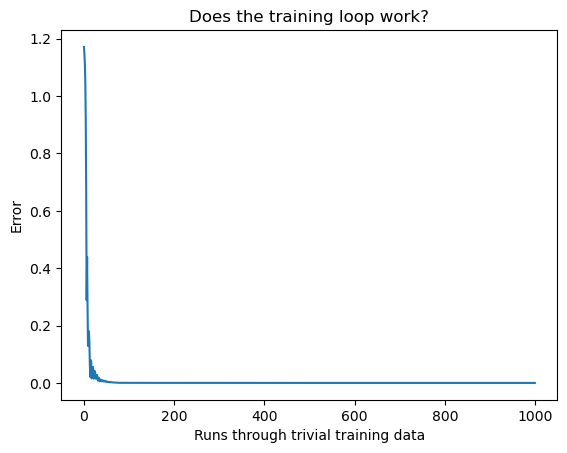

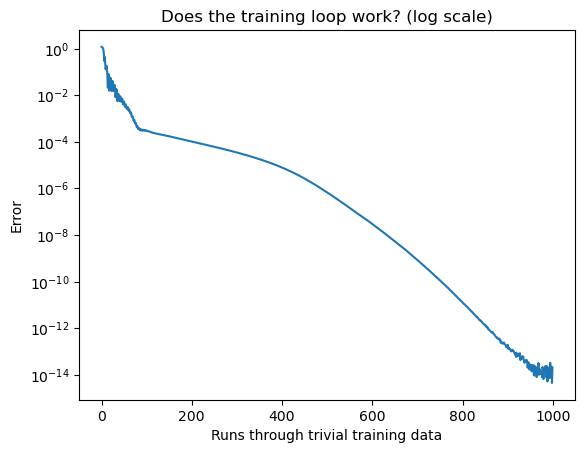

In [17]:
model0 = blank_model(choice, input_window, len(training_vars), **other_options)
optimizer0 = blank_optimizer(model0)
loss_list = []
for n in range(1000):
    y_pred = model0(xbatch)
    loss_i = loss_fn(y_pred, ybatch_01)
    optimizer0.zero_grad()
    loss_i.backward()
    optimizer0.step()
    loss_list.append(loss_i.item())
plt.plot(loss_list) 
plt.title("Does the training loop work?")
plt.xlabel("Runs through trivial training data")
plt.ylabel("Error")
plt.show()
plt.semilogy(loss_list)  
plt.title("Does the training loop work? (log scale)")
plt.xlabel("Runs through trivial training data")
plt.ylabel("Error")
plt.show()

## Training Model

In [18]:
model0

Sequential(
  (0): switch_shape()
  (1): Conv1d(36, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (2): ReLU()
  (3): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (4): ReLU()
  (5): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
  (6): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (7): ReLU()
  (8): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (9): ReLU()
  (10): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
  (11): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (12): ReLU()
  (13): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (14): ReLU()
  (15): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
  (16): AdaptiveAvgPool1d(output_size=1)
  (17): Flatten(start_dim=1, end_dim=-1)
  (18): Linear(in_features=64, out_features=32, bias=True)
  (19): ReLU()
  (20): Linear(in_features=32, out_features=1, bias=True)
)

In [19]:
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds,   batch_size=64, shuffle=False)
y_mu, y_sd = Yt[train_ind].mean(0), Yt[train_ind].std(0)

In [20]:
model = blank_model(choice, input_window, len(training_vars), **other_options)
optimizer = blank_optimizer(model)
train_history = []
val_history = []
best_error = 5000
best_epoch = 0
for epoch in range(epochs):
    if (epoch % 100) == 0:
        print(f"epoch {epoch} done")
    if (epoch - best_epoch) > patience:
        print(f"Reached patience threshold, quit on epoch {epoch}")
        break
    train_history.append(train(model, train_loader, optimizer, y_mu,y_sd, loss_fn))
    val_history.append(validate(model, val_loader,  y_mu,y_sd, loss_fn))
    if val_history[-1] < best_error:
        best_error = val_history[-1]
        best_model = copy.deepcopy(model.state_dict())
        best_epoch = epoch
model.load_state_dict(best_model)

epoch 0 done
epoch 100 done
epoch 200 done
epoch 300 done
epoch 400 done
epoch 500 done
epoch 600 done
epoch 700 done
epoch 800 done
epoch 900 done
epoch 1000 done
epoch 1100 done
epoch 1200 done
Reached patience threshold, quit on epoch 1204


<All keys matched successfully>

In [21]:
mu_val, sigma_val = unpack(evaluate(model, val_ds, y_mu,y_sd,loss_dict["eval_method"]))
truth_val = Yt[val_index[:, 0]]
print(f"Best val RMSE {torch.sqrt(((mu_val - truth_val)**2).mean()):.4f}")
print(f"Final training rmse:{float(y_sd*np.sqrt(train_history[-1])):0.4f}")

Best val RMSE 0.0287
Final training rmse:0.0332


## Graphical Checks

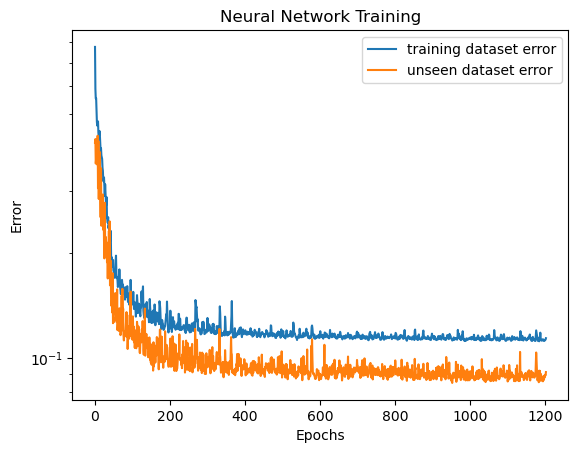

In [22]:
plt.semilogy(train_history, label = "training dataset error")
plt.semilogy(val_history, label = "unseen dataset error")
plt.xlabel("Epochs")
plt.ylabel("Error")
plt.legend()
plt.title("Neural Network Training")
plt.show()

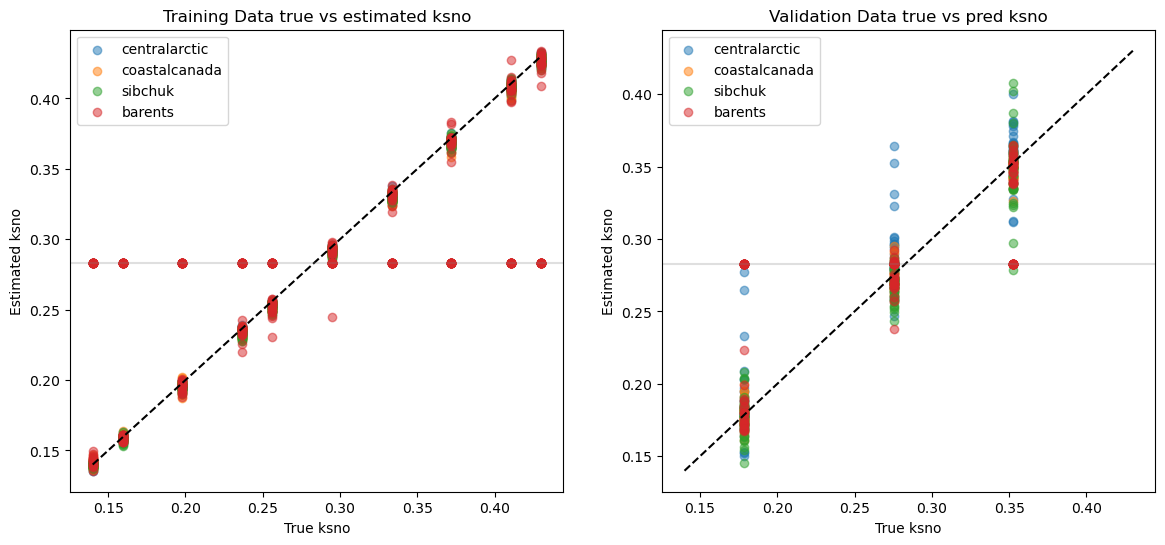

In [23]:
baseline = Yt[list(train_ind)].mean(dim = 0)
guesses_train, sigma_train =  unpack(evaluate(model,train_ds,y_mu,y_sd,loss_dict["eval_method"]))
truth_train =   Yt[train_ds.index[:,0]]
plt.rcParams['figure.figsize'] = [14, 6]
guesses_val, sigma_val =  unpack(evaluate(model,val_ds,y_mu,y_sd,loss_dict["eval_method"]))
truth_val =   Yt[val_ds.index[:,0]]
loc_val = locations[val_index[:, 0]]
loc_train = locations[train_index[:, 0]]
loc_list = ["centralarctic", "coastalcanada", "sibchuk", "barents"]
loc_index = [0,1,2,3]
loc_list = [ loc_list[i] for i in loc_index ]
plt.subplot(1,2, 1)
for loc in loc_list:
    mask = (loc_train ==loc)
    plt.scatter(truth_train[mask], guesses_train[mask], alpha=0.5, label=loc)


plt.plot(np.linspace(0.14, 0.43,100), np.linspace(0.14, 0.43,100), ls = "--", color = "black")
plt.axhline(baseline, alpha =.25, color = "grey")
plt.legend()
plt.xlabel("True ksno")
plt.ylabel("Estimated ksno")
plt.title(f"Training Data true vs estimated ksno")

plt.subplot(1, 2, 2)
for loc in loc_list:
    mask = (loc_val ==loc)
    plt.scatter(truth_val[mask], guesses_val[mask], alpha=0.5, label=loc)
plt.plot(np.linspace(0.14, 0.43,100), np.linspace(0.14, 0.43,100), ls = "--", color = "black")
plt.axhline(baseline, alpha =.25, color = "grey")
plt.legend()
plt.title(f"Validation Data true vs pred ksno")
plt.xlabel("True ksno")
plt.ylabel("Estimated ksno")
plt.show()

## Saving

In [24]:
OUT_DIR.mkdir(parents=True, exist_ok=False)
print(OUT_DIR)

/projects/dagr5998/cleaned_data/03icepack_experiment_output/ksno16/split1_enthalpy/CNN_MSE_default


In [25]:
torch.save(model.state_dict(), OUT_DIR/"model.pth")
np.save(OUT_DIR / "validation_error_history.npy", val_history)
np.save(OUT_DIR / "training_error_history.npy", train_history)
#np.save()

In [26]:
train_config = {
    "experiment_name" : EXPERIMENT_NAME,
    "run_DIR": str(IN_DIR),
    "split_dir": str(SPLIT_DIR),
    "training_vars": training_vars,
    "input_window": input_window,
    "y_mu": y_mu.tolist(),
    "y_sd": y_sd.tolist(),
    "seed": SEED,
    "batch_size": batch_size,
    "epochs":epochs,
    "patience": patience,
    "loss_choice": loss_choice,
    "model_choice": choice,
    "model_options": other_options,
    "best_epoch":best_epoch,
    "optimizer_code": inspect.getsource(blank_optimizer),
    "created": datetime.now().isoformat(timespec="seconds"),
    "best_error":float(best_error),
}
(OUT_DIR / "train_config.json").write_text(json.dumps(train_config, indent=2))

1414